In [3]:
import requests
import pandas as pd

URL = "https://www.datos.gov.co/resource/7y2j-43cv.json"

respuesta = requests.get(
    URL,
    params={"$limit": 5},
    timeout=60
)

respuesta.raise_for_status()

muestra = pd.DataFrame(respuesta.json())
display(muestra)


,pk,matricula,fecha_radica_texto,fecha_apertura_texto,year_radica,orip,divipola,departamento,municipio,tipo_predio_zona,...,num_anotacion,dinamica_2024,cod_natujur,nombre_natujur,documento_justificativo,count_a,count_de,predios_nuevos,tiene_valor,tiene_mas_de_un_valor
0,05001-001-000013-00014-00313-2018,001-13,2018-02-05 00:00:00,1973-01-11 00:00:00,2018,1,5001,ANTIOQUIA,MEDELLÍN,URBANO,...,14,0,313,CONSTITUCIÓN DE FIDEICOMISO CIVIL,01-ESCRITURA 3321 DE 22-12-2017; NOTARIA SEGUN...,2,1,0,0,0
1,05001-001-000014-00015-00313-2018,001-14,2018-02-05 00:00:00,1973-01-11 00:00:00,2018,1,5001,ANTIOQUIA,MEDELLÍN,URBANO,...,15,0,313,CONSTITUCIÓN DE FIDEICOMISO CIVIL,01-ESCRITURA 3321 DE 22-12-2017; NOTARIA SEGUN...,2,1,0,0,0
2,05001-001-000023-00007-00109-2020,001-23,2020-12-02 00:00:00,1973-01-10 00:00:00,2020,1,5001,ANTIOQUIA,MEDELLÍN,URBANO,...,7,1,109,ADJUDICACIÓN EN SUCESION,01-ESCRITURA 3322 DE 30-10-2020; NOTARIA OCTAV...,5,1,0,0,0
3,05001-001-000065-00013-00317-2015,001-65,2015-12-16 00:00:00,1973-01-10 00:00:00,2015,1,5001,ANTIOQUIA,MEDELLÍN,URBANO,...,13,1,317,CONSTITUCIÓN REGLAMENTO DE PROPIEDAD HORIZONTAL,01-ESCRITURA 8145 DE 04-12-2015; NOTARIA DIECI...,0,1,0,0,0
4,05001-001-000067-00014-00109-2016,001-67,2016-03-29 00:00:00,1973-01-11 00:00:00,2016,1,5001,ANTIOQUIA,MEDELLÍN,URBANO,...,14,1,109,ADJUDICACIÓN EN SUCESION,01-ESCRITURA 1266 DE 10-03-2016; NOTARIA DIECI...,1,1,0,0,0


In [4]:
parametros = {
    "$select": """
        municipio,
        year_radica,
        count(*) as registros
    """,
    "$where": """
        divipola in ('63001', '17001', '66001')
        AND nombre_natujur = 'COMPRAVENTA'
        AND upper(tipo_predio_zona) = 'URBANO'
        AND valor > 0
        AND tiene_mas_de_un_valor = 0
    """,
    "$group": "municipio, year_radica",
    "$order": "municipio, year_radica",
    "$limit": 50000
}

respuesta = requests.get(
    URL,
    params=parametros,
    timeout=180
)

respuesta.raise_for_status()

resumen_piloto = pd.DataFrame(respuesta.json())
resumen_piloto["registros"] = pd.to_numeric(
    resumen_piloto["registros"]
)

display(resumen_piloto)
print(f"Total de registros del piloto: {resumen_piloto['registros'].sum():,}")

,municipio,year_radica,registros
0,ARMENIA,2015,9072
1,ARMENIA,2016,10487
2,ARMENIA,2017,9478
3,ARMENIA,2018,9697
4,ARMENIA,2019,8612
5,ARMENIA,2020,8521
6,ARMENIA,2021,10942
7,ARMENIA,2022,10079
8,ARMENIA,2023,9672
9,MANIZALES,2015,7712


Total de registros del piloto: 214,036


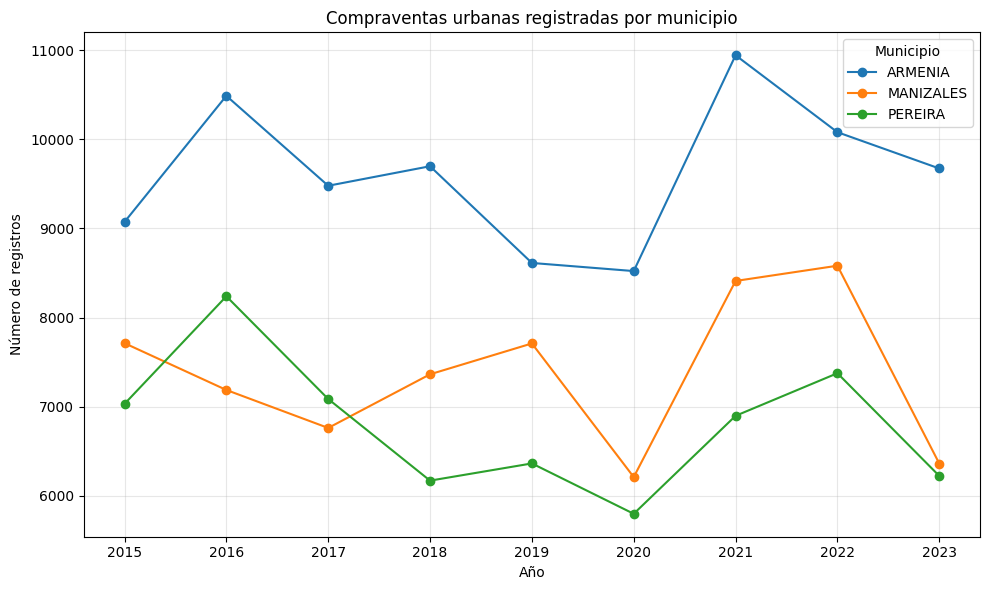

In [5]:
import matplotlib.pyplot as plt

tabla_anual = resumen_piloto.pivot(
    index="year_radica",
    columns="municipio",
    values="registros"
)

tabla_anual.plot(
    kind="line",
    marker="o",
    figsize=(10, 6)
)

plt.title("Compraventas urbanas registradas por municipio")
plt.xlabel("Año")
plt.ylabel("Número de registros")
plt.legend(title="Municipio")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(
    "figuras/compraventas_por_municipio.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [6]:
parametros_valores = {
    "$select": """
        municipio,
        year_radica,
        avg(valor) as valor_promedio,
        min(valor) as valor_minimo,
        max(valor) as valor_maximo,
        count(*) as registros
    """,
    "$where": """
        divipola in ('63001', '17001', '66001')
        AND nombre_natujur = 'COMPRAVENTA'
        AND upper(tipo_predio_zona) = 'URBANO'
        AND valor > 0
        AND tiene_mas_de_un_valor = 0
    """,
    "$group": "municipio, year_radica",
    "$order": "municipio, year_radica",
    "$limit": 50000
}

respuesta = requests.get(
    URL,
    params=parametros_valores,
    timeout=180
)

respuesta.raise_for_status()

resumen_valores = pd.DataFrame(respuesta.json())

columnas_numericas = [
    "valor_promedio",
    "valor_minimo",
    "valor_maximo",
    "registros"
]

for columna in columnas_numericas:
    resumen_valores[columna] = pd.to_numeric(
        resumen_valores[columna]
    )

display(resumen_valores)

,municipio,year_radica,valor_promedio,valor_minimo,valor_maximo,registros
0,ARMENIA,2015,8.959763e+07,50.00,12612073500,9072
1,ARMENIA,2016,8.141552e+07,125.00,9456000000,10487
2,ARMENIA,2017,8.616724e+07,200000.00,4925000200,9478
3,ARMENIA,2018,7.747081e+07,67290.00,4000000000,9697
4,ARMENIA,2019,1.037652e+08,22832.00,4104372990,8612
5,ARMENIA,2020,1.132043e+08,800000.00,3300000000,8521
6,ARMENIA,2021,1.098886e+08,160000.00,4200000000,10942
7,ARMENIA,2022,1.151503e+08,160000.00,7299999700,10079
8,ARMENIA,2023,1.458283e+08,600000.00,17614671900,9672
9,MANIZALES,2015,4.743903e+08,2438.08,49290047000,7712


In [7]:
resumen_legible = resumen_valores.copy()

for columna in [
    "valor_promedio",
    "valor_minimo",
    "valor_maximo"
]:
    resumen_legible[columna] = resumen_legible[columna].map(
        lambda valor: f"${valor:,.0f}"
    )

display(resumen_legible)

,municipio,year_radica,valor_promedio,valor_minimo,valor_maximo,registros
0,ARMENIA,2015,"$89,597,629",$50,"$12,612,073,500",9072
1,ARMENIA,2016,"$81,415,523",$125,"$9,456,000,000",10487
2,ARMENIA,2017,"$86,167,238","$200,000","$4,925,000,200",9478
3,ARMENIA,2018,"$77,470,811","$67,290","$4,000,000,000",9697
4,ARMENIA,2019,"$103,765,198","$22,832","$4,104,372,990",8612
5,ARMENIA,2020,"$113,204,269","$800,000","$3,300,000,000",8521
6,ARMENIA,2021,"$109,888,649","$160,000","$4,200,000,000",10942
7,ARMENIA,2022,"$115,150,258","$160,000","$7,299,999,700",10079
8,ARMENIA,2023,"$145,828,328","$600,000","$17,614,671,900",9672
9,MANIZALES,2015,"$474,390,267","$2,438","$49,290,047,000",7712


In [8]:
LIMITE = 50000
offset = 0
paginas = []

filtro_piloto = """
    divipola in ('63001', '17001', '66001')
    AND nombre_natujur = 'COMPRAVENTA'
    AND upper(tipo_predio_zona) = 'URBANO'
    AND valor > 0
    AND tiene_mas_de_un_valor = 0
"""

while True:
    parametros_detalle = {
        "$select": "municipio, year_radica, valor",
        "$where": filtro_piloto,
        "$order": "municipio, year_radica",
        "$limit": LIMITE,
        "$offset": offset
    }

    respuesta = requests.get(
        URL,
        params=parametros_detalle,
        timeout=180
    )

    respuesta.raise_for_status()

    pagina = pd.DataFrame(respuesta.json())

    if pagina.empty:
        break

    paginas.append(pagina)

    print(
        f"Descargados {len(pagina):,} registros "
        f"desde el offset {offset:,}"
    )

    if len(pagina) < LIMITE:
        break

    offset += LIMITE

datos_piloto = pd.concat(
    paginas,
    ignore_index=True
)

datos_piloto["valor"] = pd.to_numeric(
    datos_piloto["valor"]
)

print(
    f"Total descargado: {len(datos_piloto):,} registros"
)

Descargados 50,000 registros desde el offset 0
Descargados 50,000 registros desde el offset 50,000
Descargados 50,000 registros desde el offset 100,000
Descargados 50,000 registros desde el offset 150,000
Descargados 14,036 registros desde el offset 200,000
Total descargado: 214,036 registros


In [9]:
datos_piloto.to_csv("datos_inmobiliarios.csv", index=False)

In [10]:
resumen_distribucion = (
    datos_piloto
    .groupby("municipio")["valor"]
    .agg(
        registros="count",
        mediana="median",
        promedio="mean",
        minimo="min",
        maximo="max"
    )
    .reset_index()
)

resumen_distribucion["p25"] = (
    datos_piloto.groupby("municipio")["valor"]
    .quantile(0.25)
    .values
)

resumen_distribucion["p75"] = (
    datos_piloto.groupby("municipio")["valor"]
    .quantile(0.75)
    .values
)

resumen_distribucion

,municipio,registros,mediana,promedio,minimo,maximo,p25,p75
0,ARMENIA,86560,68000000.0,1.016156e+08,50.00,1.761467e+10,22000000.0,122000000.0
1,MANIZALES,66295,99000000.0,2.102389e+08,1.00,3.841362e+11,36000000.0,169000000.0
2,PEREIRA,61181,92500000.0,2.838544e+08,471.56,3.780000e+11,45000000.0,160000000.0


In [11]:
mediana_anual = (
    datos_piloto
    .groupby(["municipio", "year_radica"])["valor"]
    .median()
    .reset_index(name="valor_mediano")
)

tabla_mediana = mediana_anual.pivot(
    index="year_radica",
    columns="municipio",
    values="valor_mediano"
)

display(tabla_mediana)

municipio,ARMENIA,MANIZALES,PEREIRA
year_radica,,,
2015,45104500.0,83100000.0,79736000.0
2016,48261848.0,80000000.0,86450000.0
2017,57500000.0,90000000.0,81875000.0
2018,56086000.0,102500000.0,82325000.0
2019,70000000.0,123177128.0,95000000.0
2020,70000000.0,95875000.0,95000000.0
2021,77500000.0,90000000.0,103000000.0
2022,81200000.0,100000000.0,122600000.0
2023,108000000.0,135000000.0,123000000.0


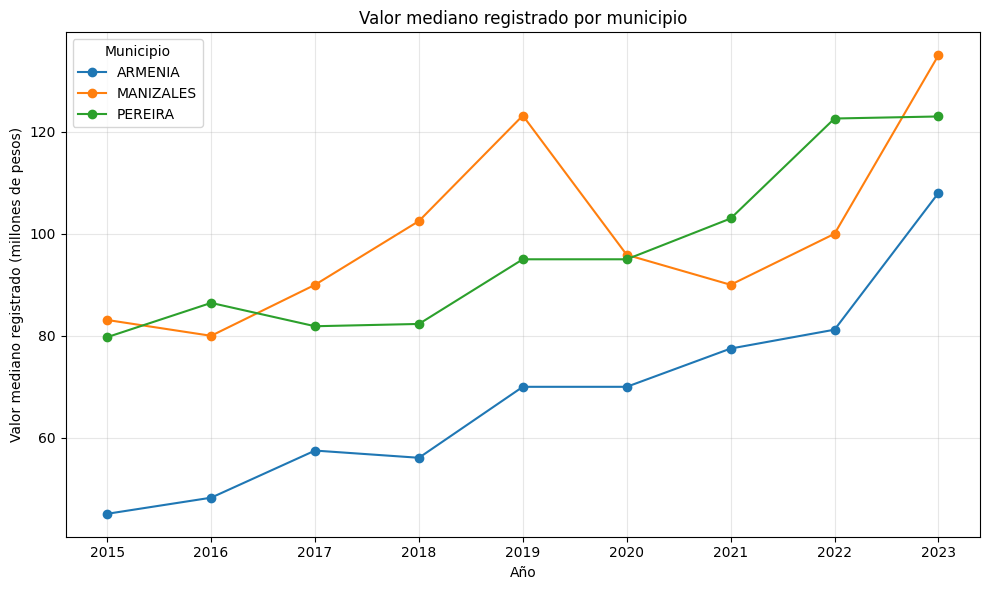

In [12]:
from pathlib import Path

Path("figuras").mkdir(exist_ok=True)

tabla_mediana_millones = tabla_mediana / 1_000_000

tabla_mediana_millones.plot(
    kind="line",
    marker="o",
    figsize=(10, 6)
)

plt.title("Valor mediano registrado por municipio")
plt.xlabel("Año")
plt.ylabel("Valor mediano registrado (millones de pesos)")
plt.legend(title="Municipio")
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    "figuras/valor_mediano_por_municipio.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()